# Linear Regression in Finance: NumPy vs. scikit-learn

This notebook applies linear regression to two classic quantitative-finance problems and solves each one two ways: by hand with **NumPy** (via the normal equation) and with **scikit-learn**'s `LinearRegression`. The goal is to confirm both approaches agree, and to see what each one buys you in practice.

1. **CAPM beta estimation** — simple linear regression of a stock's excess returns on the market's excess returns.
2. **Multi-factor return model** — multiple linear regression of a stock's returns on several risk factors (Fama-French style).

Since this notebook needs to run offline and reproducibly, the "market" and "stock" return series are simulated with a fixed random seed rather than downloaded. The simulation is built so the true relationship (the beta, the factor loadings) is known in advance, which makes it easy to check that both regression methods recover it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True

RNG = np.random.default_rng(42)

## Part 1 — CAPM: estimating a stock's beta

The Capital Asset Pricing Model says a stock's excess return is approximately a linear function of the market's excess return:

$$ r_{stock} - r_f = \alpha + \beta (r_{market} - r_f) + \varepsilon $$

$\beta$ measures the stock's sensitivity to the market (systematic risk); $\alpha$ is the excess return not explained by the market. Both are usually estimated by ordinary least squares (OLS) regression of stock excess returns on market excess returns — this is just simple linear regression.

In [2]:
# --- Simulate daily returns for the market and one stock -------------------
n_days = 1000
true_alpha = 0.0003      # ~7.5% annualized alpha
true_beta = 1.35         # stock is more volatile than the market

market_returns = RNG.normal(loc=0.0004, scale=0.010, size=n_days)
idio_noise = RNG.normal(loc=0.0, scale=0.006, size=n_days)
stock_returns = true_alpha + true_beta * market_returns + idio_noise

dates = pd.bdate_range('2021-01-04', periods=n_days)
returns = pd.DataFrame({'market': market_returns, 'stock': stock_returns}, index=dates)
returns.head()

,market,stock
2021-01-04,0.003447,0.004598
2021-01-05,-0.010000,-0.017576
2021-01-06,0.007905,0.008484
2021-01-07,0.009806,0.017341
2021-01-08,-0.019110,-0.025481


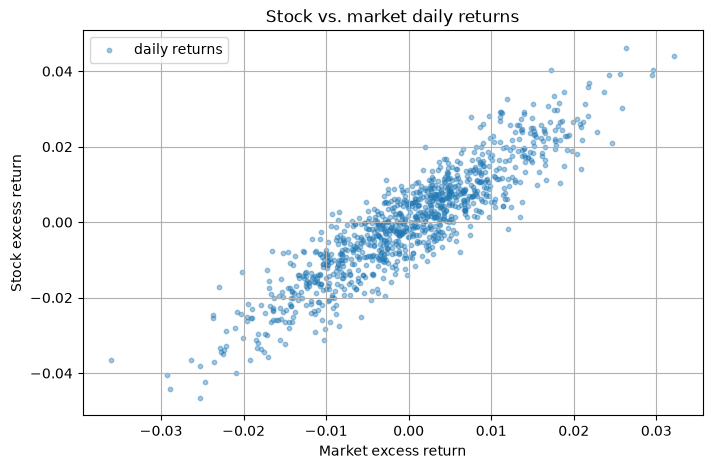

In [3]:
fig, ax = plt.subplots()
ax.scatter(returns['market'], returns['stock'], s=10, alpha=0.4, label='daily returns')
ax.set_xlabel('Market excess return')
ax.set_ylabel('Stock excess return')
ax.set_title('Stock vs. market daily returns')
ax.legend()
plt.show()

### Model A — NumPy (normal equation)

OLS has a closed-form solution: $\hat{\theta} = (X^\top X)^{-1} X^\top y$, where $X$ has a column of ones prepended for the intercept. We implement this directly with `numpy.linalg`.

In [4]:
X_market = returns['market'].values
y_stock = returns['stock'].values

# design matrix: [1, x] for each observation
X_design = np.column_stack([np.ones_like(X_market), X_market])

# normal equation: theta = (X'X)^-1 X'y
theta_np = np.linalg.inv(X_design.T @ X_design) @ X_design.T @ y_stock
alpha_np, beta_np = theta_np

print(f"NumPy  alpha = {alpha_np:.6f}   beta = {beta_np:.4f}")

NumPy  alpha = -0.000188   beta = 1.3451


### Model B — scikit-learn

`LinearRegression` solves the same least-squares problem internally (via SVD), but handles the intercept and matrix bookkeeping for us.

In [5]:
X_sk = X_market.reshape(-1, 1)  # sklearn expects a 2D feature matrix

capm_model = LinearRegression()
capm_model.fit(X_sk, y_stock)

alpha_sk = capm_model.intercept_
beta_sk = capm_model.coef_[0]

print(f"sklearn alpha = {alpha_sk:.6f}   beta = {beta_sk:.4f}")

sklearn alpha = -0.000188   beta = 1.3451


In [6]:
comparison = pd.DataFrame({
    'true': [true_alpha, true_beta],
    'numpy': [alpha_np, beta_np],
    'sklearn': [alpha_sk, beta_sk],
}, index=['alpha', 'beta'])
comparison['numpy_vs_sklearn_diff'] = comparison['numpy'] - comparison['sklearn']
comparison

,true,numpy,sklearn,numpy_vs_sklearn_diff
alpha,0.0003,-0.000188,-0.000188,2.981556e-19
beta,1.3500,1.345142,1.345142,-6.661338e-16


NumPy and scikit-learn recover essentially identical coefficients (differences at the level of floating-point noise), and both land close to the true simulated `alpha`/`beta` — the gap is just idiosyncratic noise in a finite sample. Let's overlay the fitted line on the scatter plot to see the fit visually, plus the classic annualized-alpha framing finance people actually care about.

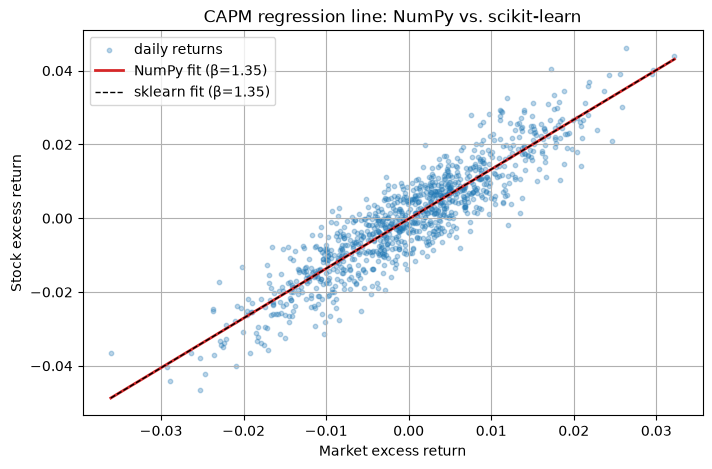

Estimated beta: 1.35  ->  stock moves 1.35x the market on average
Estimated annualized alpha: -4.73%


In [7]:
x_line = np.linspace(returns['market'].min(), returns['market'].max(), 100)
y_line_np = alpha_np + beta_np * x_line
y_line_sk = capm_model.predict(x_line.reshape(-1, 1))

fig, ax = plt.subplots()
ax.scatter(returns['market'], returns['stock'], s=10, alpha=0.3, label='daily returns')
ax.plot(x_line, y_line_np, color='tab:red', lw=2, label=f'NumPy fit (β={beta_np:.2f})')
ax.plot(x_line, y_line_sk, color='black', lw=1, ls='--', label=f'sklearn fit (β={beta_sk:.2f})')
ax.set_xlabel('Market excess return')
ax.set_ylabel('Stock excess return')
ax.set_title('CAPM regression line: NumPy vs. scikit-learn')
ax.legend()
plt.show()

annualized_alpha = alpha_np * 252
print(f"Estimated beta: {beta_np:.2f}  ->  stock moves {beta_np:.2f}x the market on average")
print(f"Estimated annualized alpha: {annualized_alpha:.2%}")

The two fitted lines are on top of each other, as expected — for ordinary least squares on a well-conditioned problem, the normal equation and scikit-learn's solver converge to the same optimum.

## Part 2 — Multi-factor return model

Single-factor CAPM leaves a lot of return variation unexplained. In practice, quants extend it with more factors — e.g. a Fama-French-style model with **market**, **size (SMB)**, and **value (HML)** factors:

$$ r_{stock} = \alpha + \beta_1 \cdot \text{MKT} + \beta_2 \cdot \text{SMB} + \beta_3 \cdot \text{HML} + \varepsilon $$

This is multiple linear regression — same idea as Part 1, just with more columns in $X$. We'll also do a proper train/test split here, since with more parameters overfitting becomes a real concern.

In [8]:
# --- Simulate three risk factors and a stock driven by all three -----------
n_days2 = 1500
true_coefs = {'alpha': 0.0002, 'MKT': 1.10, 'SMB': 0.45, 'HML': -0.30}

mkt = RNG.normal(0.0004, 0.010, n_days2)
smb = RNG.normal(0.0000, 0.006, n_days2)
hml = RNG.normal(0.0000, 0.006, n_days2)
noise = RNG.normal(0.0, 0.004, n_days2)

stock_multi = (true_coefs['alpha']
               + true_coefs['MKT'] * mkt
               + true_coefs['SMB'] * smb
               + true_coefs['HML'] * hml
               + noise)

factors = pd.DataFrame({'MKT': mkt, 'SMB': smb, 'HML': hml, 'stock': stock_multi},
                        index=pd.bdate_range('2019-01-02', periods=n_days2))
factors.head()

,MKT,SMB,HML,stock
2019-01-02,-0.004120,-0.001461,-0.001548,0.000480
2019-01-03,-0.006259,0.007933,-0.001797,0.003220
2019-01-04,0.004740,0.003815,-0.004180,0.019585
2019-01-07,0.002919,-0.007143,0.002571,0.002457
2019-01-08,-0.013648,0.000969,0.001408,-0.014147


In [9]:
feature_cols = ['MKT', 'SMB', 'HML']
X_all = factors[feature_cols].values
y_all = factors['stock'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, shuffle=False  # keep chronological order
)
print(f"Train: {X_train.shape[0]} days   Test: {X_test.shape[0]} days")

Train: 1200 days   Test: 300 days


### Model A — NumPy (normal equation, multi-feature)

The exact same formula as before, `theta = (X'X)^-1 X'y`, works unchanged for multiple features — that's the appeal of writing it in matrix form.

In [10]:
X_train_design = np.column_stack([np.ones(X_train.shape[0]), X_train])
theta_multi_np = np.linalg.inv(X_train_design.T @ X_train_design) @ X_train_design.T @ y_train
alpha_multi_np, *betas_multi_np = theta_multi_np

X_test_design = np.column_stack([np.ones(X_test.shape[0]), X_test])
y_pred_np = X_test_design @ theta_multi_np

print("NumPy coefficients:")
for name, val in zip(['alpha'] + feature_cols, theta_multi_np):
    print(f"  {name:6s} = {val: .5f}")

NumPy coefficients:
  alpha  =  0.00010
  MKT    =  1.10850
  SMB    =  0.42640
  HML    = -0.28926


### Model B — scikit-learn (multi-feature)

In [11]:
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_sk = multi_model.predict(X_test)

print("sklearn coefficients:")
print(f"  alpha  = {multi_model.intercept_: .5f}")
for name, val in zip(feature_cols, multi_model.coef_):
    print(f"  {name:6s} = {val: .5f}")

sklearn coefficients:
  alpha  =  0.00010
  MKT    =  1.10850
  SMB    =  0.42640
  HML    = -0.28926


In [12]:
coef_table = pd.DataFrame({
    'true': [true_coefs['alpha'], true_coefs['MKT'], true_coefs['SMB'], true_coefs['HML']],
    'numpy': theta_multi_np,
    'sklearn': [multi_model.intercept_, *multi_model.coef_],
}, index=['alpha'] + feature_cols)
coef_table

,true,numpy,sklearn
alpha,0.0002,0.000096,0.000096
MKT,1.1000,1.108504,1.108504
SMB,0.4500,0.426405,0.426405
HML,-0.3000,-0.289264,-0.289264


### Out-of-sample evaluation

Coefficients matching is reassuring, but what matters in practice is out-of-sample predictive accuracy. We compute MSE and $R^2$ on the held-out test set for both models — implemented manually with NumPy, and via `sklearn.metrics` — to double check the two give the same numbers.

In [13]:
def mse_manual(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def r2_manual(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

metrics = pd.DataFrame({
    'NumPy (manual)': [mse_manual(y_test, y_pred_np), r2_manual(y_test, y_pred_np)],
    'NumPy (sklearn.metrics)': [mean_squared_error(y_test, y_pred_np), r2_score(y_test, y_pred_np)],
    'sklearn model (sklearn.metrics)': [mean_squared_error(y_test, y_pred_sk), r2_score(y_test, y_pred_sk)],
}, index=['MSE', 'R2'])
metrics

,NumPy (manual),NumPy (sklearn.metrics),sklearn model (sklearn.metrics)
MSE,0.000016,0.000016,0.000016
R2,0.884417,0.884417,0.884417


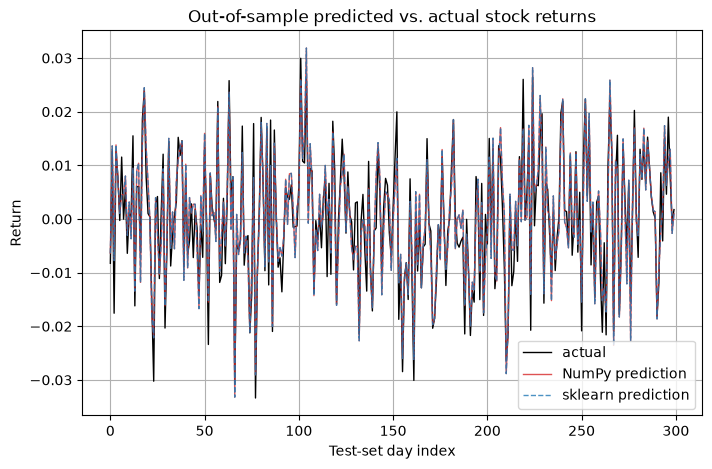

Max |prediction diff| between NumPy and sklearn: 5.20e-17


In [14]:
fig, ax = plt.subplots()
ax.plot(y_test, label='actual', color='black', lw=1)
ax.plot(y_pred_np, label='NumPy prediction', color='tab:red', lw=1, alpha=0.8)
ax.plot(y_pred_sk, label='sklearn prediction', color='tab:blue', lw=1, ls='--', alpha=0.8)
ax.set_title('Out-of-sample predicted vs. actual stock returns')
ax.set_xlabel('Test-set day index')
ax.set_ylabel('Return')
ax.legend()
plt.show()

print(f"Max |prediction diff| between NumPy and sklearn: {np.max(np.abs(y_pred_np - y_pred_sk)):.2e}")

## Takeaways

- **Numerically, they agree.** Both the single-factor CAPM regression and the multi-factor model produce coefficients and predictions that match between the hand-rolled NumPy normal-equation solver and scikit-learn's `LinearRegression`, up to floating-point precision. That's expected: both are solving the same least-squares problem, and scikit-learn's OLS is a normal-equation/SVD solve under the hood too.
- **NumPy** is worth reaching for when you want to see the mechanics — the normal equation makes the linear-algebra structure of OLS explicit, which is useful for teaching, for deriving standard errors/confidence intervals by hand, or for tight loops where you don't want the overhead of a general-purpose estimator API. Its downside: it has no built-in train/test tooling, regularization, or numerical safeguards — `(X'X)^-1` can become unstable if factors are highly correlated (multicollinearity), which is a real risk with financial factors.
- **scikit-learn** is the better choice for actual workflows: consistent `fit`/`predict` API, integrates with `train_test_split`, cross-validation, pipelines, and regularized variants (`Ridge`, `Lasso`) that handle multicollinearity gracefully — a one-line swap if the factors turn out to be collinear.
- In quant finance, this exact pattern — regress an asset's returns on one or more factor returns — is the basis of CAPM beta estimation, Fama-French/Carhart factor models, and hedge-ratio calculations. The techniques above generalize directly to those use cases with real market data in place of the simulated series.